# OpenMC → pyMPPost collision file

Reads the OpenMC `tracks.h5` file and writes an MCNPX-PoliMi style collision file for pyMPPost.

pyMPPost can be downloaded from: https://gitlab.eecs.umich.edu/umich-dnng/pymppost

Neutrons and photons are always analysed separately: set `PARTICLE` in the configuration cell.

In [1]:
import os
import sys
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.colors import LogNorm

In [2]:
# Make the src/ folder importable
sys.path.append(os.path.abspath("/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/src"))

import openmc
from TrackAnalyzer import build_analyzer, describe_history, particle_name

In [3]:
# ================================ CONFIGURATION ================================
PARTICLE         = "photon"          # "neutron" | "photon"  (never both)
DETECTOR         = "nai"         # key of DETECTOR_LIBRARY
DETECTOR_MAT_IDS = [99]               # OpenMC material ID(s) of the detector


BASE_DIR   = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost"
CASE = "sodium-iodide/152Eu"
TRACK_DIR  = "/Volumes/PortableSSD/DATA/2026/UM-OPENMC-PYMPPOST-METHODOLOGY/" + CASE
TRACK_FILE = "OpenMC_tracks_1.0E5.h5"

# Incident energy below which events are not written [eV].
# For photons keep it >= the OpenMC photon energy cutoff (default 1 keV).
E_THRESHOLD_EV = {"neutron": 1e1, "photon": 1e3}

# Same meaning as the cards of the MCNPX-PoliMi input of this case:
# RPOL : (1) neutron, (2) photon thresholds on the deposited energy [MeV];
#        collisions that deposit less are not written, 0 = write every energy release
# IPOL_CELLS : cells for which collisions are written, as IPOL(7)-(8...) but with the
#        OpenMC cell IDs (IPOL(7) = number of cells in the list); None = every cell
RPOL       = (0, 0)
IPOL_CELLS = [20]

MAX_RESIDUAL   = 0.05     # neutrons: tolerance on |predicted - measured| E'/E
WRITE_COHERENT = False    # photons: write coherent scattering events (Edep = 0)
N_INSPECT      = 10       # number of initial histories printed in verbose mode

# Detector descriptions
#   neutron_targets: nuclide -> atomic weight ratio (A) and ZAID written in the file
#   photon_zaid    : representative ZAID written for photon interactions
DETECTOR_LIBRARY = {
    "stilbene": {
        "neutron_targets": {"H-1":  {"A": 0.99917, "zaid": 1001},
                            "C-12": {"A": 11.8969, "zaid": 6000}},
        "photon_zaid": 6000,
    },

    "helium4": {
        "neutron_targets": {"He-4":  {"A":3.968, "zaid": 2004}},
        "photon_zaid": 6000,
    },    

    "nai": {
        "neutron_targets": {"Na-23": {"A": 22.792, "zaid": 11023},
                            "I-127": {"A": 126.9045, "zaid": 53127}},
        "photon_zaid": 53000,
    },    
}
# ===============================================================================

RESULTS_DIR = os.path.join(BASE_DIR, "results", CASE)
TRACK_PATH  = os.path.join(TRACK_DIR, TRACK_FILE)
DET         = DETECTOR_LIBRARY[DETECTOR]

# Count the histories without loading the track data
with h5py.File(TRACK_PATH, "r") as fh:
    SOURCE_PARTICLES = sum(1 for key in fh.keys() if key.startswith("track_"))
print(f"Total source particles: {SOURCE_PARTICLES / 1e5}E5")


Total source particles: 1.0E5


# Analysis

In [4]:
# Optional: list every particle of one history (type, birth energy and position).
# For photons, check that electrons/positrons appear: the photoelectric and
# pair-production reconstruction relies on them.
describe_history(TRACK_PATH, index=2)

History #2 (track_1_1_3): 2 particle tracks
  P #0   photon    states=3    E0=4.5413e+04 eV  r0=(0.0000, 0.0000, -1.0000)  E_end=0.0000e+00 eV
  P #1   photon    states=3    E0=2.8610e+04 eV  r0=(0.0000, 0.0000, 0.0114)  E_end=2.8610e+04 eV


In [5]:
output_path = os.path.join(
    RESULTS_DIR, f"OpenMC_collision_file_{PARTICLE}_{DETECTOR}_{SOURCE_PARTICLES / 1e5}E5.d")

# Particle-specific options
extra = ({"max_residual": MAX_RESIDUAL} if PARTICLE == "neutron"
         else {"write_coherent": WRITE_COHERENT})

analyzer = build_analyzer(PARTICLE, DET,
                          Ethreshold=E_THRESHOLD_EV[PARTICLE],
                          rpol=RPOL,
                          polimi_file_path=output_path,
                          **extra)

n_hist = analyzer.process_file(TRACK_PATH,
                               target_materials=DETECTOR_MAT_IDS,
                               target_cells=IPOL_CELLS,
                               n_inspect=N_INSPECT)

print(f"\nProcessed histories: {n_hist}")
print(f"Collision file     : {output_path}")
analyzer.summary()


========== HISTORY #0 ==========
  [H #0 | P #0] Event at state 2 (code 1): ✓ Compton
    Energy: 3.443e+05 eV → 2.185e+05 eV | Edep = 1.258e+05 eV
    Secondary photons born at site: 0.000e+00 eV
  ------------------------------------------------
  [H #0 | P #0] Event at state 3 (code 3): ✓ Photoelectric
    Energy: 2.185e+05 eV → 0.000e+00 eV | Edep = 2.185e+05 eV
    Secondary photons born at site: 0.000e+00 eV
  ------------------------------------------------
  → [H #0 | P #0] End of track: 4 states, final energy 0.00e+00 eV

========== HISTORY #1 ==========
  → [H #1 | P #0] No valid events in materials [99] in cells [20].
  → [H #1 | P #0] End of track: 4 states, final energy 1.41e+06 eV

========== HISTORY #2 ==========
  [H #2 | P #0] Event at state 2 (code 3): ✓ Photoelectric
    Energy: 4.541e+04 eV → 0.000e+00 eV | Edep = 1.680e+04 eV
    Secondary photons born at site: 2.861e+04 eV
  ------------------------------------------------
  → [H #2 | P #0] End of track: 3 states

In [6]:
for i in range(10):
    describe_history(TRACK_PATH, index=i)

History #0 (track_1_1_1): 1 particle tracks
  P #0   photon    states=4    E0=3.4428e+05 eV  r0=(0.0000, 0.0000, -1.0000)  E_end=0.0000e+00 eV
History #1 (track_1_1_2): 1 particle tracks
  P #0   photon    states=4    E0=1.4080e+06 eV  r0=(0.0000, 0.0000, -1.0000)  E_end=1.4080e+06 eV
History #2 (track_1_1_3): 2 particle tracks
  P #0   photon    states=3    E0=4.5413e+04 eV  r0=(0.0000, 0.0000, -1.0000)  E_end=0.0000e+00 eV
  P #1   photon    states=3    E0=2.8610e+04 eV  r0=(0.0000, 0.0000, 0.0114)  E_end=2.8610e+04 eV
History #3 (track_1_1_4): 1 particle tracks
  P #0   photon    states=4    E0=1.4080e+06 eV  r0=(0.0000, 0.0000, -1.0000)  E_end=1.4080e+06 eV
History #4 (track_1_1_5): 1 particle tracks
  P #0   photon    states=3    E0=4.0119e+04 eV  r0=(0.0000, 0.0000, -1.0000)  E_end=0.0000e+00 eV
History #5 (track_1_1_6): 1 particle tracks
  P #0   photon    states=4    E0=1.2991e+06 eV  r0=(0.0000, 0.0000, -1.0000)  E_end=1.2991e+06 eV
History #6 (track_1_1_7): 1 particle tracks


Histories with deposits : 91412
Full-energy fraction    : 0.000
Full-energy efficiency  : 3.200e-04 per source photon


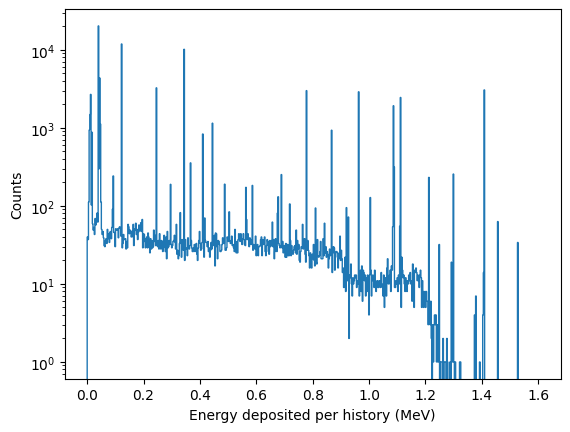

In [7]:
# Total energy deposited per history (no resolution): the 661.7 keV photopeak must appear
import pandas as pd
import matplotlib.pyplot as plt

coll = pd.read_csv(output_path, sep=r"\s+", header=None, usecols=[0, 6],
                   names=["history", "edep_MeV"])
edep_hist = coll.groupby("history")["edep_MeV"].sum()

peak = (edep_hist - 0.661657).abs() < 0.001
print(f"Histories with deposits : {len(edep_hist)}")
print(f"Full-energy fraction    : {peak.mean():.3f}")
print(f"Full-energy efficiency  : {peak.sum() / SOURCE_PARTICLES:.3e} per source photon")

plt.hist(edep_hist, bins=700, range=(0, 1.6), histtype="step")
plt.yscale("log"); plt.xlabel("Energy deposited per history (MeV)"); plt.ylabel("Counts")
plt.show()